In [ ]:
print("Hello, Customer Churn ML!")
print(10 + 20)

Hello, Customer Churn ML!
30


**Libraries install**

In [ ]:

%pip install -q pandas numpy scikit-learn joblib matplotlib seaborn streamlit fastapi "uvicorn[standard]" pytest httpx


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 72.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 74.9 MB/s eta 0:00:00


## 1. Dataset Loading

In this step, we will load the Telco Customer Churn dataset from a public online source using the Pandas library.

The dataset contains customer information such as tenure, contract type, internet services, monthly charges, total charges, and churn status.

The target column, `Churn`, tells us whether a customer has left the company (`Yes`) or stayed (`No`).

**Objective:**
- Load the dataset into a Pandas DataFrame.
- Check the number of rows and columns.
- Display the first five records.
- Understand the distribution of customers who churned and those who stayed.

This dataset will be used to train a machine learning classification model that predicts customer churn.

In [ ]:

import pandas as pd

# URL of the public Telco Customer Churn dataset
url = (
    "https://huggingface.co/spaces/bolbo1/crm/"
    "resolve/main/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

# Load the CSV file into a Pandas DataFrame
df = pd.read_csv(url)

# Display basic information about the dataset
print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

# Display the first five records
display(df.head())

# Display the target column distribution
print("\nChurn Distribution:")
display(df["Churn"].value_counts())


Dataset loaded successfully!
Number of rows and columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Churn Distribution:


,count
Churn,
No,5174
Yes,1869


## 2. Data Understanding

In this step, we will perform an initial inspection of the Telco Customer Churn dataset to understand its structure and quality.

Before training a machine learning model, it is important to know what information is available and whether the dataset contains missing values, duplicate records, or incorrect data types.

**Objectives:**
- Check the number of rows and columns.
- Understand column names and data types.
- Identify missing values.
- Check duplicate records.
- Review summary statistics for numerical and categorical columns.

This analysis will help us decide which data-cleaning and preprocessing steps are required before model training.

In [ ]:

# 1. Check the dataset dimensions
print("Dataset Shape:", df.shape)

# 2. Display all column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Check data types and non-null counts
print("\nDataset Information:")
df.info()

# 4. Count missing values in each column
print("\nMissing Values:")
display(df.isnull().sum().sort_values(ascending=False))

# 5. Count duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# 6. Generate summary statistics
print("\nNumerical Summary:")
display(df.describe())

print("\nCategorical Summary:")
display(df.describe(include="object").T)


Dataset Shape: (7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Duplicate Rows: 0

Numerical Summary:


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000



Categorical Summary:


,count,unique,top,freq
customerID,7043,7043,3186-AJIEK,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


## 3. Exploratory Data Analysis (EDA): Churn Distribution

Exploratory Data Analysis (EDA) helps us understand patterns in our dataset before training a machine learning model.

In this step, we will examine the distribution of customers who left the service and customers who stayed.

**Objectives:**
- Count customers in each churn category.
- Calculate the percentage of churned and retained customers.
- Visualize the target variable using a bar chart.
- Understand whether the target classes are imbalanced.

Class imbalance matters because a model can achieve high accuracy while still failing to identify customers who actually churn.

Customer Churn Counts:


,count
Churn,
No,5174
Yes,1869



Customer Churn Percentages:


,proportion
Churn,
No,73.46
Yes,26.54


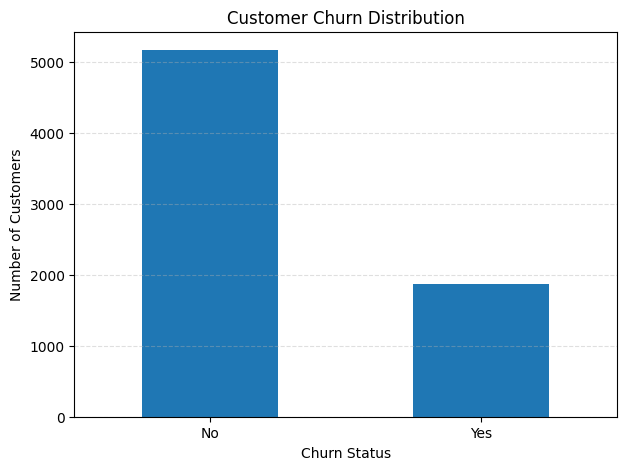

In [ ]:

import matplotlib.pyplot as plt

# 1. Count customers in each churn category
churn_counts = df["Churn"].value_counts()

print("Customer Churn Counts:")
display(churn_counts)

# 2. Calculate percentages
churn_percentages = df["Churn"].value_counts(normalize=True) * 100

print("\nCustomer Churn Percentages:")
display(churn_percentages.round(2))

# 3. Create a bar chart
plt.figure(figsize=(7, 5))

churn_counts.plot(kind="bar")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.show()


## 4. Exploratory Data Analysis: Factors Affecting Churn

In this step, we will explore how customer characteristics relate to churn.

We will analyze three important features:

- **Contract:** The type of contract selected by the customer.
- **Tenure:** The number of months the customer has stayed with the company.
- **MonthlyCharges:** The amount charged to the customer each month.

We will compare these features across churn categories to identify patterns that may help predict customer churn.

**Note:** These are associations in the dataset, not proof that a particular feature causes customers to leave.

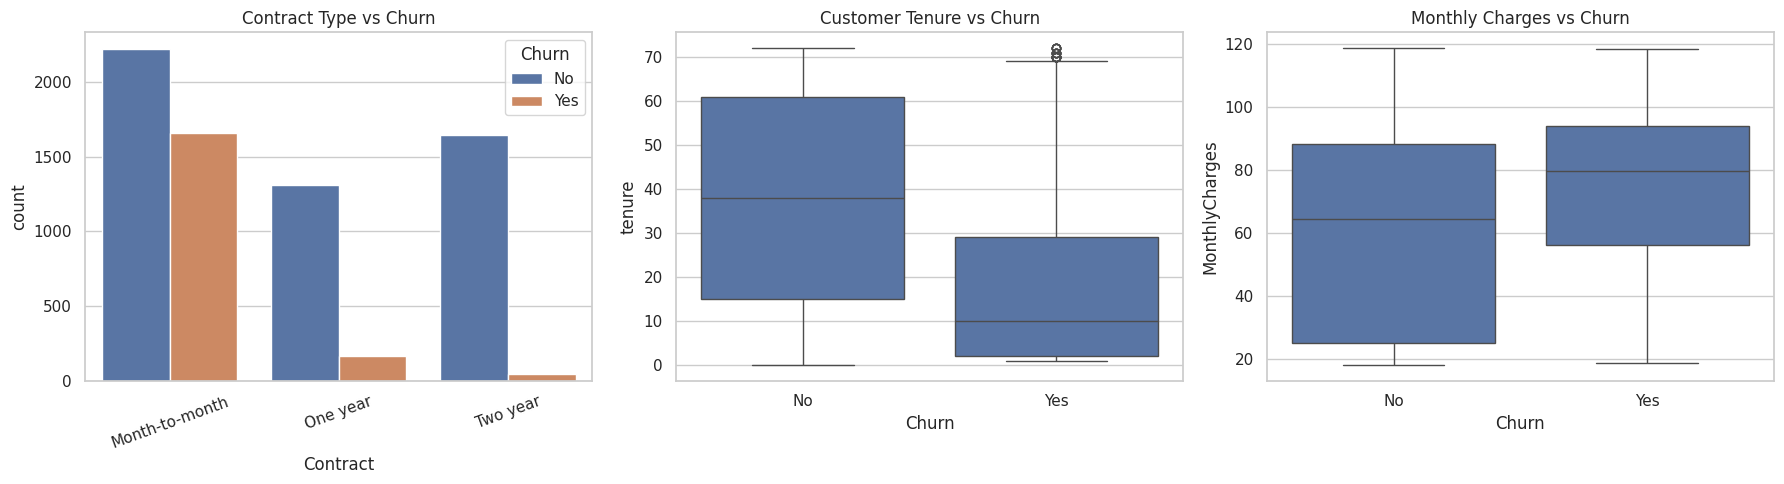

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

# Set the chart style
sns.set_theme(style="whitegrid")

# Create three charts side by side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Chart 1: Contract type vs churn
sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[0])
axes[0].set_title("Contract Type vs Churn")
axes[0].tick_params(axis="x", rotation=20)

# Chart 2: Tenure vs churn
sns.boxplot(data=df, x="Churn", y="tenure", ax=axes[1])
axes[1].set_title("Customer Tenure vs Churn")

# Chart 3: Monthly charges vs churn
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[2])
axes[2].set_title("Monthly Charges vs Churn")

plt.tight_layout()
plt.show()


In [8]:

# Compare average tenure and monthly charges by churn status
print("Average Tenure and Monthly Charges by Churn Status:")

display(
    df.groupby("Churn")[["tenure", "MonthlyCharges"]]
      .mean()
      .round(2)
)

# Compare churn rate across contract types
print("\nChurn Rate by Contract Type (%):")

contract_churn_rate = (
    df.assign(Churn_Flag=(df["Churn"] == "Yes").astype(int))
      .groupby("Contract")["Churn_Flag"]
      .mean()
      .mul(100)
      .round(2)
)

display(contract_churn_rate)


Average Tenure and Monthly Charges by Churn Status:


,tenure,MonthlyCharges
Churn,,
No,37.57,61.27
Yes,17.98,74.44



Churn Rate by Contract Type (%):


,Churn_Flag
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


## 5. Data Cleaning and Preparation

Real-world datasets can contain missing values, inconsistent data types, and duplicate records. These issues can affect machine learning model performance.

In this step, we will:

- Remove unnecessary whitespace from column names and text values.
- Convert `TotalCharges` into a numeric column.
- Identify missing values and duplicate rows.
- Handle missing values safely.
- Verify that the dataset is ready for model training.

We will keep the original target column, `Churn`, because it identifies whether a customer left the service.

In [10]:

# Import pandas
import pandas as pd

# 1. Create a copy so the original dataset remains unchanged
df_clean = df.copy()

# 2. Remove extra spaces from column names
df_clean.columns = df_clean.columns.str.strip()

# 3. Remove extra spaces from text columns
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()

# 4. Convert TotalCharges to numeric
# Invalid or blank values will become NaN
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

# 5. Check missing values after conversion
print("Missing values before handling:")
display(df_clean.isnull().sum().sort_values(ascending=False).head(10))

# 6. Check duplicate rows
print("Duplicate rows:", df_clean.duplicated().sum())

# 7. Remove duplicate rows, if any
df_clean = df_clean.drop_duplicates().copy()

# 8. Check the dataset after cleaning
print("\nCleaned dataset shape:", df_clean.shape)
print("\nData types:")
display(df_clean.dtypes)


Missing values before handling:


,0
TotalCharges,11
gender,0
SeniorCitizen,0
Partner,0
customerID,0
Dependents,0
tenure,0
MultipleLines,0
PhoneService,0
OnlineSecurity,0


Duplicate rows: 0

Cleaned dataset shape: (7043, 21)

Data types:


,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [11]:

# 1. Identify numerical and categorical columns
numeric_cols = df_clean.select_dtypes(include="number").columns.tolist()
categorical_cols = df_clean.select_dtypes(include="object").columns.tolist()

# 2. Fill missing numerical values with the median
for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# 3. Fill missing categorical values with the most frequent value
for col in categorical_cols:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].mode()[0]
        )

# 4. Verify that missing values have been handled
print("Total missing values remaining:", df_clean.isnull().sum().sum())

print("Final dataset shape:", df_clean.shape)

# 5. Check the target column
print("\nChurn categories:")
display(df_clean["Churn"].value_counts())


Total missing values remaining: 0
Final dataset shape: (7043, 21)

Churn categories:


,count
Churn,
No,5174
Yes,1869


## 6. Train-Test Split and Data Preprocessing

Machine learning models require data in a suitable numerical format.

In this step, we will:

- Separate the target variable (`Churn`) from the input features.
- Remove `customerID`, which is an identifier rather than a useful predictive feature.
- Split the dataset into training and testing sets.
- Identify numerical and categorical features.
- Create a preprocessing pipeline to handle missing values, scale numerical features, and encode categorical features.

We will use 80% of the data for training and 20% for testing. The test data will be kept separate so that we can evaluate the model on customers it did not train on.

In [12]:

from sklearn.model_selection import train_test_split

# 1. Separate the target from input features
X = df_clean.drop(columns=["Churn", "customerID"])
y = df_clean["Churn"].map({"No": 0, "Yes": 1})

# 2. Check that the target was converted correctly
print("Target values:")
display(y.value_counts())

# 3. Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 4. Display dataset sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)


Target values:


,count
Churn,
0,5174
1,1869


Training features: (5634, 19)
Testing features: (1409, 19)
Training labels: (5634,)
Testing labels: (1409,)


In [13]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Identify numerical and categorical columns from training data
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

# Numerical preprocessing:
# Fill missing values and scale numerical data
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing:
# Fill missing values and convert categories into numerical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct preprocessing to each type of feature
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("\nPreprocessing pipeline created successfully!")


Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Preprocessing pipeline created successfully!


## 7. Model Training

In this step, we will train two supervised machine learning classification models to predict customer churn.

**Models:**
1. **Logistic Regression:** A simple, interpretable classification algorithm that provides a useful baseline.
2. **Random Forest:** An ensemble model that combines multiple decision trees to learn patterns in the data.

We will combine each model with our preprocessing pipeline so that data transformation and prediction happen consistently.

After training, we will compare their performance using classification metrics in the next step.

In [14]:

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# 1. Create the Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

# 2. Create the Random Forest pipeline
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# 3. Train Logistic Regression
print("Training Logistic Regression...")
logistic_model.fit(X_train, y_train)
print("Logistic Regression training completed!")

# 4. Train Random Forest
print("\nTraining Random Forest...")
random_forest_model.fit(X_train, y_train)
print("Random Forest training completed!")

# 5. Store both trained models
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

print("\nBoth models are ready for evaluation!")


Training Logistic Regression...
Logistic Regression training completed!

Training Random Forest...
Random Forest training completed!

Both models are ready for evaluation!


In [15]:

# Check that both models can make predictions
for model_name, model in models.items():
    predictions = model.predict(X_test)

    print(f"{model_name}:")
    print("Test predictions generated:", len(predictions))
    print("First 10 predictions:", predictions[:10])
    print("-" * 40)


Logistic Regression:
Test predictions generated: 1409
First 10 predictions: [0 1 0 0 0 1 0 0 0 0]
----------------------------------------
Random Forest:
Test predictions generated: 1409
First 10 predictions: [0 1 0 0 0 0 0 0 0 0]
----------------------------------------


## 8. Model Evaluation

After training, we need to evaluate how well our models perform on unseen test data.

We will use the following metrics:

- **Accuracy:** Percentage of all predictions that are correct.
- **Precision:** Of the customers predicted to churn, how many actually churned?
- **Recall:** Of the customers who actually churned, how many did the model identify?
- **F1-score:** A combined measure of precision and recall.
- **ROC-AUC:** Measures how well the model separates churned and retained customers across different probability thresholds.
- **Confusion Matrix:** Shows correct and incorrect predictions for both classes.

Recall is particularly important in churn prediction because failing to identify a customer who is about to leave may mean losing an opportunity to retain them.

In [16]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Store evaluation results for both models
results = []

for model_name, model in models.items():

    # Predict churn labels
    y_pred = model.predict(X_test)

    # Predict churn probabilities
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

# Display results in a table
results_df = pd.DataFrame(results).set_index("Model")

display(results_df.round(4))


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8419
Random Forest,0.7842,0.6224,0.4759,0.5394,0.8223


In [28]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

y_pred = best_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

if hasattr(best_model, "predict_proba"):
    y_prob = best_model.predict_proba(X_test)[:, 1]
    print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))


Accuracy: 0.8055
Precision: 0.6572
Recall: 0.5588
F1 Score: 0.604
ROC-AUC: 0.8419


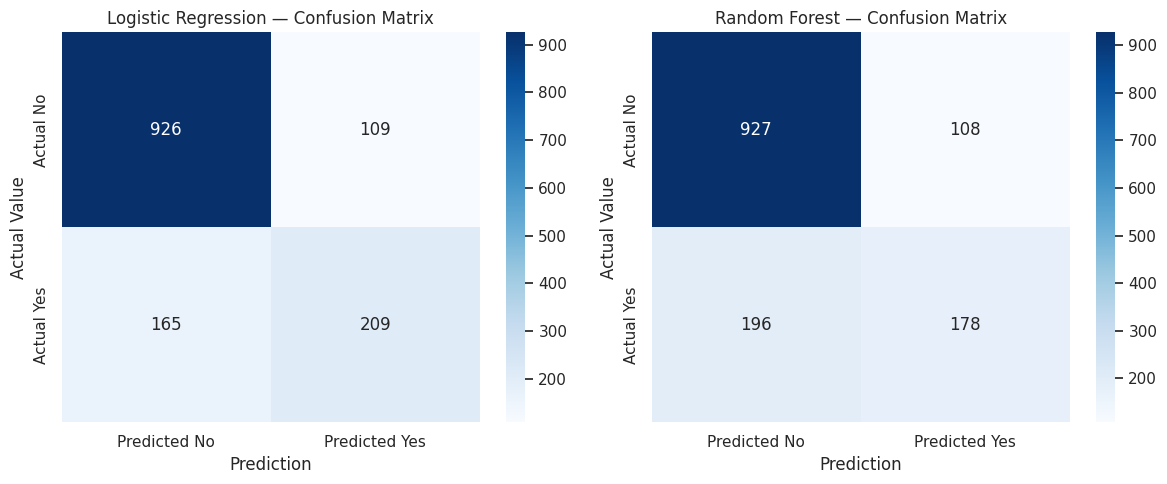

In [29]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (model_name, model) in zip(axes, models.items()):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Predicted No", "Predicted Yes"],
        yticklabels=["Actual No", "Actual Yes"],
        ax=ax
    )

    ax.set_title(f"{model_name} — Confusion Matrix")
    ax.set_xlabel("Prediction")
    ax.set_ylabel("Actual Value")

plt.tight_layout()
plt.show()


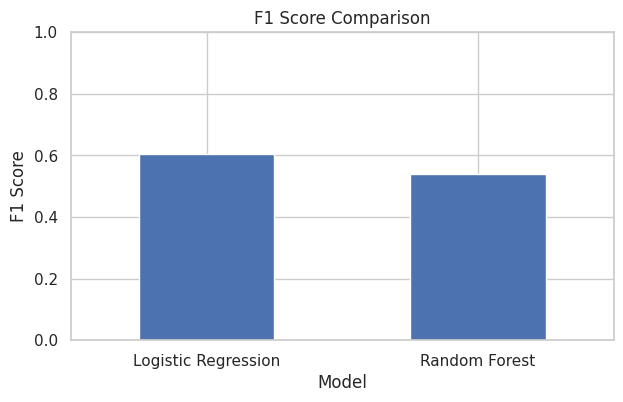

In [30]:

# Compare F1-scores visually
results_df["F1 Score"].plot(
    kind="bar",
    figsize=(7, 4),
    title="F1 Score Comparison"
)

plt.ylabel("F1 Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.show()


## 9. Best Model Selection and Model Persistence

In this step, we will select a model using its F1-score, with recall and ROC-AUC as additional evaluation criteria.

We will then save the selected preprocessing-and-model pipeline so that it can be reused without retraining every time the application starts.

Finally, we will test the saved model on a sample customer record.

The saved artifact will be used in the Streamlit dashboard and FastAPI service in later project stages.

In [27]:

# Select the model with the highest F1-score
best_model_name = results_df["F1 Score"].idxmax()
best_model = models[best_model_name]

# Display the selected model and its metrics
print("Selected Model:", best_model_name)
print("\nSelected Model Metrics:")
display(results_df.loc[[best_model_name]].round(4))


Selected Model: Logistic Regression

Selected Model Metrics:


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8055,0.6572,0.5588,0.604,0.8419


In [20]:

import joblib
import os

# Create a folder for project artifacts
os.makedirs("artifacts", exist_ok=True)

# Save the complete preprocessing + model pipeline
model_path = "artifacts/churn_prediction_pipeline.joblib"

joblib.dump(best_model, model_path)

print("Model saved successfully!")
print("Saved location:", model_path)
print("File size:", round(os.path.getsize(model_path) / 1024, 2), "KB")


Model saved successfully!
Saved location: artifacts/churn_prediction_pipeline.joblib
File size: 8.37 KB


In [21]:

# Load the saved pipeline
loaded_model = joblib.load(model_path)

# Select one customer from the test dataset
sample_customer = X_test.iloc[[0]]

# Predict churn and churn probability
prediction = loaded_model.predict(sample_customer)[0]
churn_probability = loaded_model.predict_proba(sample_customer)[0, 1]

print("Prediction:", "Likely to Churn" if prediction == 1 else "Likely to Stay")
print(f"Estimated Churn Probability: {churn_probability:.2%}")

print("\nCustomer Features:")
display(sample_customer)


Prediction: Likely to Stay
Estimated Churn Probability: 4.52%

Customer Features:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.2


In [22]:

# Verify that the saved pipeline can predict multiple customers
reloaded_predictions = loaded_model.predict(X_test)

print("Total test customers:", len(X_test))
print("Predictions generated:", len(reloaded_predictions))
print("Model artifact exists:", os.path.exists(model_path))


Total test customers: 1409
Predictions generated: 1409
Model artifact exists: True


## 10. Building a Customer Churn Prediction Dashboard

We will build an interactive web dashboard using Streamlit.

**Dashboard features:**
- Enter customer details using form controls.
- Predict whether a customer is likely to churn.
- Display the estimated churn probability.
- Provide a simple, user-friendly interface for model predictions.

The dashboard will load the saved machine learning pipeline, which includes preprocessing and the trained classifier. This allows new customer records to be processed consistently with the training data.

**Technology stack:** Python, Pandas, Scikit-learn, Joblib, and Streamlit.

In [23]:

%%writefile app.py

import streamlit as st
import pandas as pd
import joblib
from pathlib import Path

# Load the saved machine learning pipeline
MODEL_PATH = Path(__file__).parent / "artifacts" / "churn_prediction_pipeline.joblib"
model = joblib.load(MODEL_PATH)

# Configure the dashboard
st.set_page_config(
    page_title="Customer Churn Prediction",
    page_icon="📊",
    layout="wide"
)

st.title("📊 Customer Churn Prediction")
st.write(
    "Enter customer details below to estimate their likelihood "
    "of leaving the telecom service."
)

st.info("Demo application using a trained machine learning model.")

# Create a customer information form
with st.form("customer_form"):

    st.subheader("Customer Information")

    col1, col2 = st.columns(2)

    with col1:
        gender = st.selectbox("Gender", ["Female", "Male"])
        senior_citizen = st.selectbox("Senior Citizen", [0, 1])
        partner = st.selectbox("Has Partner?", ["Yes", "No"])
        dependents = st.selectbox("Has Dependents?", ["Yes", "No"])

        tenure = st.number_input(
            "Tenure (months)",
            min_value=0,
            max_value=72,
            value=12
        )

        phone_service = st.selectbox("Phone Service", ["Yes", "No"])

        multiple_lines = st.selectbox(
            "Multiple Lines",
            ["No", "Yes", "No phone service"]
        )

        internet_service = st.selectbox(
            "Internet Service",
            ["DSL", "Fiber optic", "No"]
        )

    with col2:
        online_security = st.selectbox(
            "Online Security",
            ["Yes", "No", "No internet service"]
        )

        online_backup = st.selectbox(
            "Online Backup",
            ["Yes", "No", "No internet service"]
        )

        device_protection = st.selectbox(
            "Device Protection",
            ["Yes", "No", "No internet service"]
        )

        tech_support = st.selectbox(
            "Tech Support",
            ["Yes", "No", "No internet service"]
        )

        streaming_tv = st.selectbox(
            "Streaming TV",
            ["Yes", "No", "No internet service"]
        )

        streaming_movies = st.selectbox(
            "Streaming Movies",
            ["Yes", "No", "No internet service"]
        )

    st.subheader("Billing and Contract")

    col3, col4 = st.columns(2)

    with col3:
        contract = st.selectbox(
            "Contract Type",
            ["Month-to-month", "One year", "Two year"]
        )

        paperless_billing = st.selectbox(
            "Paperless Billing",
            ["Yes", "No"]
        )

        payment_method = st.selectbox(
            "Payment Method",
            [
                "Electronic check",
                "Mailed check",
                "Bank transfer (automatic)",
                "Credit card (automatic)"
            ]
        )

    with col4:
        monthly_charges = st.number_input(
            "Monthly Charges",
            min_value=0.0,
            max_value=1000.0,
            value=70.0,
            step=1.0
        )

        total_charges = st.number_input(
            "Total Charges",
            min_value=0.0,
            max_value=100000.0,
            value=840.0,
            step=10.0
        )

    submitted = st.form_submit_button(
        "Predict Customer Churn",
        use_container_width=True
    )

# Run prediction when the form is submitted
if submitted:

    customer_data = pd.DataFrame([{
        "gender": gender,
        "SeniorCitizen": senior_citizen,
        "Partner": partner,
        "Dependents": dependents,
        "tenure": tenure,
        "PhoneService": phone_service,
        "MultipleLines": multiple_lines,
        "InternetService": internet_service,
        "OnlineSecurity": online_security,
        "OnlineBackup": online_backup,
        "DeviceProtection": device_protection,
        "TechSupport": tech_support,
        "StreamingTV": streaming_tv,
        "StreamingMovies": streaming_movies,
        "Contract": contract,
        "PaperlessBilling": paperless_billing,
        "PaymentMethod": payment_method,
        "MonthlyCharges": monthly_charges,
        "TotalCharges": total_charges
    }])

    prediction = int(model.predict(customer_data)[0])
    probability = float(model.predict_proba(customer_data)[0, 1])

    st.subheader("Prediction Result")

    metric_col1, metric_col2 = st.columns(2)

    with metric_col1:
        if prediction == 1:
            st.error("Prediction: Likely to Churn")
        else:
            st.success("Prediction: Likely to Stay")

    with metric_col2:
        st.metric(
            "Estimated Churn Probability",
            f"{probability:.1%}"
        )

    st.progress(probability)

    st.caption(
        "This is a model estimate, not a guarantee. "
        "Use it as decision support rather than a definitive conclusion."
    )

st.divider()
st.caption("Customer Churn Prediction | Python • Scikit-learn • Streamlit")


Writing app.py


In [24]:

from importlib.metadata import version

# Pin versions compatible with the model trained in this notebook
requirements = [
    f"pandas=={version('pandas')}",
    f"scikit-learn=={version('scikit-learn')}",
    f"joblib=={version('joblib')}",
    "streamlit>=1.35,<2.0"
]

with open("requirements.txt", "w") as file:
    file.write("\n".join(requirements) + "\n")

print("requirements.txt created:")
print("\n".join(requirements))


requirements.txt created:
pandas==2.2.3
scikit-learn==1.6.1
joblib==1.6.0
streamlit>=1.35,<2.0


In [25]:

import os
import py_compile

# Check that the saved model exists
assert os.path.exists(
    "artifacts/churn_prediction_pipeline.joblib"
), "Model file is missing. Run Step 9 again."

# Check that the dashboard code exists
assert os.path.exists("app.py"), "app.py was not created."

# Check Python syntax without launching the app
py_compile.compile("app.py", doraise=True)

print("App file exists: True")
print("Model file exists: True")
print("Requirements file exists:", os.path.exists("requirements.txt"))
print("Python syntax check: PASSED")


App file exists: True
Model file exists: True
Requirements file exists: True
Python syntax check: PASSED


**Step 11 — Package the project**

In [26]:

import os
import zipfile
from google.colab import files

# 1. Create a project folder
project_folder = "customer-churn-prediction"
os.makedirs(project_folder, exist_ok=True)
os.makedirs(f"{project_folder}/artifacts", exist_ok=True)

# 2. Copy the application and requirements files
import shutil

shutil.copy("app.py", f"{project_folder}/app.py")
shutil.copy("requirements.txt", f"{project_folder}/requirements.txt")

# 3. Copy the trained model
shutil.copy(
    "artifacts/churn_prediction_pipeline.joblib",
    f"{project_folder}/artifacts/churn_prediction_pipeline.joblib"
)

# 4. Create a README file
readme_text = """# Customer Churn Prediction

An end-to-end machine learning project that predicts telecom
customer churn using Scikit-learn and Streamlit.

## Features
- Customer churn prediction
- Estimated churn probability
- Logistic Regression and Random Forest comparison
- Saved preprocessing and prediction pipeline

## Technology Stack
- Python
- Pandas
- Scikit-learn
- Joblib
- Streamlit

## Run Locally

Install the dependencies:

    pip install -r requirements.txt

Start the dashboard:

    streamlit run app.py

## Model
The trained pipeline is stored at:
artifacts/churn_prediction_pipeline.joblib

## Disclaimer
Predictions are estimates, not guarantees. This project is
for educational and demonstration purposes.
"""

with open(f"{project_folder}/README.md", "w", encoding="utf-8") as file:
    file.write(readme_text)

# 5. Package all project files into a ZIP
zip_name = "customer-churn-prediction.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zf:
    for root, dirs, filenames in os.walk(project_folder):
        for filename in filenames:
            full_path = os.path.join(root, filename)
            archive_path = os.path.relpath(full_path, project_folder)
            zf.write(full_path, archive_path)

print("Project ZIP created successfully!")
print("Files included:")
for root, dirs, filenames in os.walk(project_folder):
    for filename in filenames:
        print(os.path.relpath(os.path.join(root, filename), project_folder))

# 6. Download the ZIP to your computer
files.download(zip_name)


Project ZIP created successfully!
Files included:
README.md
requirements.txt
app.py
artifacts/churn_prediction_pipeline.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>